# BMAD Continual Learning: Colab driver (v4.1, split-integrity release)
**Peter Ozo-ogueji · with Prof. Roberto Corizzo (AU)**

This notebook only *drives* the experiments. All logic lives in the tested repository `bmad-continual-learning` (package `bmad_cl`, 53 unit tests, CI). See the repository README for the scenario and protocol, and `docs/DATA.md` for the dataset card.

| Part | What it does |
|---|---|
| 0 | GPU check, Drive, run switches |
| 1 | Get the code (GitHub, or the zip on your Drive), run the test suite here, install Mammoth (pinned) and the plugin |
| 2 | Data: restore the cached BMAD from Drive (or download, resize and cache it once) |
| 3 | Inspect the train/val/test splits, sample images, **source-confound check**, pipeline test |
| 4 | Experiments: **tune on validation → select → final runs on test (3 seeds) → task order** |
| 5 | Report: tables with 95% intervals, paired comparisons, bootstrap intervals, figures, provenance |
| 6 | Optional: PyCLAD (off by default) |

### What's new in v4.1
v4's run showed that about 90% of Camelyon16's training normals came from tumour-free slides, while its test normals came from tumour slides, a source mismatch that made the single-category Histopathology model fail (AUROC 0.48 on one seed). **Training normals now come first from the same patient/slide groups as the test normals**; ID-less training images only fill a shortfall, and in practice none are needed. Leakage protection is unchanged. Results go to a new folder, `CL_BMAD_project/v4_1`, and v4 stays untouched.

### What was new in v4
An audit of the real BMAD filenames found patient-level leakage risks in three categories, and v4 fixes them:
- **Chest:** grouped by the RSNA patient ID in each filename (one radiograph per patient). v3 grouped every abnormal file under one "patient" and fell back to image-level splitting.
- **OCT2017:** grouped by the patient number in `DISEASE-PATIENT-IMAGE` filenames. v3 treated every image as its own patient.
- **RESC and Camelyon16:** BMAD's training images carry no IDs, so they now go into our **training split only**. Camelyon16's other patches (no slide ID) are grouped in contiguous blocks of 25, an approximation of slides that is stated as a limitation.
- **New audits in Part 3:** group overlap and duplicate files across splits (the notebook stops if any group crosses splits), and a shortcut test (can image statistics alone predict the label?).
- **Statistics:** bootstrap intervals now resample whole patients, volumes or blocks.
- **EWC:** validation's second-best setting (λ = 10) runs as a labelled sensitivity analysis.

Because the splits changed, v4 reran everything: about 6 hours, across several sessions. Run all resumes where it stopped.

### Earlier releases
#### v3.1
- **Joint-Train reference fixed:** its learning rate and a step-decay schedule are now tuned on validation (Stage 3b). With the shared constant learning rate, joint training was unstable between seeds (e.g. Brain 94.9% in one seed, 52.9% in another), so it was not a valid upper bound.
- **Crashed runs are reported, not hidden or retried:** EWC seed 0 diverged (NaN loss). It now appears as "2 (+1 incomplete)" and in `incomplete_runs.csv`, and **Run all** won't silently re-attempt it.
- Joint-Train predictions are now saved, so they get bootstrap intervals too.
- Code comes from the `CL_BMAD/bmad-continual-learning` folder on your Drive; all cells are self-contained.

**Run all is safe:** every finished run (tuning, 3 seeds, task order) is skipped automatically, so only the new Joint-Train runs execute (about 30 minutes).

### What changed in v3 (and why the numbers changed)
- **Validation split:** hyperparameters are tuned on validation; the test set is used only once, for the final runs. Before, the only held-out data was the test set.
- **Liver source confound fixed:** BMAD's liver *training* normals come from a different source dataset (BTCV) than all of its labeled images (LiTS). Earlier versions mixed them, so "normal" partly meant "came from BTCV". Liver normals now come only from LiTS.
- **Confidence intervals and paired comparisons**, plus provenance (environment, GPU, commits) saved for every run.

v1/v2 results used different splits and are **not comparable** with v3. They stay untouched on your Drive; v3 writes to `MyDrive/CL_BMAD/v3`.

> **How to run:** `Runtime → Change runtime type → T4 GPU`, then **`Runtime → Run all`**. Every stage is resumable: if Colab disconnects, **Run all** again and finished runs are skipped.

## Part 0 — Setup

In [ ]:
!nvidia-smi --query-gpu=name,memory.total --format=csv || echo "No GPU: Runtime > Change runtime type > T4 GPU"
import os, sys, torch
print('torch', torch.__version__, '| CUDA:', torch.cuda.is_available(), '| python', sys.version.split()[0])

name, memory.total [MiB]
Tesla T4, 15360 MiB
torch 2.11.0+cu130 | CUDA: True | python 3.13.16


In [ ]:
from google.colab import drive
drive.mount('/content/drive', force_remount=True)

import os
DRIVE_DIR = '/content/drive/MyDrive/CL_BMAD_project'   # renamed from CL_BMAD (a stale duplicate CL_BMAD exists)
# Guard: stop immediately if Colab can't see the real project folder (wrong account or wrong folder)
_tar = f'{DRIVE_DIR}/BMAD_224.tar'
assert os.path.exists(_tar) and os.path.getsize(_tar) > 10**9, (
    f'Project files not found in {DRIVE_DIR}. Check the mounted Google account, then re-run this cell.')
OUT       = f'{DRIVE_DIR}/v4_1'                       # v4.1 outputs (new splits: never mixed with earlier runs)
REPO_DIR  = '/content/bmad-continual-learning'
REPO_URL  = 'https://github.com/PeterOzo/bmad-continual-learning.git'   # after you push the repository
REPO_ZIP  = f'{DRIVE_DIR}/bmad-continual-learning.zip'                 # or: upload the zip here
MAMMOTH   = '/content/mammoth'
BMAD_RAW  = '/content/BMAD_raw'
BMAD      = '/content/BMAD_224'
CACHE     = f'{DRIVE_DIR}/BMAD_224.tar'               # resized BMAD from your earlier sessions
os.makedirs(OUT, exist_ok=True)

# ---- run switches ------------------------------------------------------------------------
RUN_TUNING     = True        # stage 1: 10 validation runs, ~1.3 h
SEEDS          = [0, 1, 2]   # stage 3: ~1 h per seed
RUN_TASK_ORDER = True        # stage 4: ~35 min
RUN_JOINT_TUNING = True      # stage 3b: 5 validation runs + 3 final runs, ~30 min
RUN_EWC_SENSITIVITY = True   # stage 3c: EWC lambda = 10 on 3 seeds, ~25 min
RUN_PYCLAD     = False

def bmad_ready(min_images=1000):
    if not os.path.isdir(BMAD):
        return False
    n = 0
    for _, _, fs in os.walk(BMAD):
        n += len(fs)
        if n >= min_images:
            return True
    return False
print('Outputs ->', OUT)

Mounted at /content/drive
Outputs -> /content/drive/MyDrive/CL_BMAD_project/v4_1


## Part 1 — Code: repository, tests, Mammoth
The code is **embedded in this notebook** as a checksummed bundle, so nothing needs to be uploaded or synced. The checksum is verified on unpacking and recorded with every run. **The test suite then runs here in Colab**, so a broken environment is caught before any training starts.

In [ ]:
# Embedded code bundle: the bmad-continual-learning repository (26 files), base64 of a .tar.gz
BUNDLE_B64 = '...'

In [ ]:
# Unpack the embedded repository, verify its checksum, install it
import base64, hashlib, io, tarfile, shutil
BUNDLE_SHA256 = '7c0a388abc7bb86df71287e293194a00cb19b9afd51fc154f4b15258e5c03c6d'
raw = base64.b64decode(BUNDLE_B64)
assert hashlib.sha256(raw).hexdigest() == BUNDLE_SHA256, 'Code bundle corrupted: download the notebook again.'
shutil.rmtree(REPO_DIR, ignore_errors=True)
with tarfile.open(fileobj=io.BytesIO(raw), mode='r:gz') as t:
    t.extractall('/content', filter='data')
os.environ['BMAD_CL_BUNDLE_SHA256'] = BUNDLE_SHA256    # recorded in every run's provenance file
!pip install -q -e "{REPO_DIR}[report]"
sys.path.insert(0, f'{REPO_DIR}/src')
import bmad_cl; print('bmad_cl', bmad_cl.__version__, '| bundle sha256', BUNDLE_SHA256[:16], '...')

  Installing build dependencies ... done
  Checking if build backend supports build_editable ... done
  Getting requirements to build editable ... done
  Preparing editable metadata (pyproject.toml) ... done
  Building editable for bmad-cl (pyproject.toml) ... done
bmad_cl 0.4.1 | bundle sha256 7c0a388abc7bb86d ...


In [ ]:
# Run the repository's test suite in this exact environment (about 20 seconds)
!cd {REPO_DIR} && MPLBACKEND=Agg python -m pytest -q 2>&1 | tail -3

........................................................................ [ 80%]
.................                                                        [100%]


In [ ]:
# Mammoth, pinned; open_clip is imported by several Mammoth dataset files at startup
!rm -rf {MAMMOTH} && git clone -q https://github.com/aimagelab/mammoth.git {MAMMOTH}
!cd {MAMMOTH} && git checkout -q e75a491c69fd729edeb01431afb753d9157d9a81 && git log -1 --format='Mammoth commit %h (%cd)'
!pip install -q -r {MAMMOTH}/requirements.txt open_clip_torch
!cp {REPO_DIR}/mammoth_plugin/seq_bmad.py {MAMMOTH}/datasets/seq_bmad.py && echo "Plugin installed"

Mammoth commit e75a491 (Wed May 20 22:13:32 2026 +0200)
Plugin installed


## Part 2 — Data
Restores the resized BMAD from your Drive cache (about a minute). The download, unzip and resize steps run only if no cache exists.

In [ ]:
if bmad_ready():
    print('BMAD ready at', BMAD)
elif os.path.exists(CACHE):
    !tar -xf "{CACHE}" -C /content
    print('Restored from Drive cache:', bmad_ready())
else:
    print('No cache: downloading (~21 GB), unzipping and resizing (~25 min, first time only)')
    !pip install -q --upgrade gdown
    import gdown, glob, subprocess
    os.makedirs('/content/bmad_zips', exist_ok=True)
    gdown.download_folder(url='https://drive.google.com/drive/folders/1AC-wWZl_K18CWL2eIxUScoSOoxT4IBuw',
                          output='/content/bmad_zips', quiet=False, resume=True)
    os.makedirs(BMAD_RAW, exist_ok=True)
    for a in glob.glob('/content/bmad_zips/**/*.zip', recursive=True):
        subprocess.run(['unzip', '-q', '-n', a, '-d', BMAD_RAW], check=False)
    from bmad_cl import resize
    resize.resize_tree(BMAD_RAW, BMAD, size=(224, 224))
    assert bmad_ready(), 'No resized images: check the download.'
    !tar -cf "{CACHE}" -C /content BMAD_224 && ls -lh "{CACHE}"

Restored from Drive cache: True


## Part 3 — Inspect the scenario
Expect, for every category: balanced train/val/test splits, **zero group overlap between any two splits**, Liver using `used_train_normals = 0` (the confound fix), and a `grouping` column showing the independence unit used (`patient`, `id` = volume/subject, `block`, `trainonly`).

In [ ]:
import pandas as pd
from bmad_cl import index as BI, analysis as A, experiments as E, report, envinfo
CATS = BI.parse_order(BI.DEFAULT_ORDER)
print('Dataset folders:', [os.path.relpath(p, BMAD) for p in BI.candidate_roots(BMAD)])
rows = []
for k in CATS:
    c = BI.build_category(BMAD, k, seed=0)
    s = c['stats']
    rows.append({'task': len(rows) + 1, 'category': c['name'], 'folder': os.path.relpath(c['dir'], BMAD),
                 'train n/a': f"{s['final_train_normal']}/{s['final_train_abnormal']}",
                 'val n/a': f"{s['final_val_normal']}/{s['final_val_abnormal']}",
                 'test n/a': f"{s['final_test_normal']}/{s['final_test_abnormal']}",
                 'patient groups': s['n_groups'],
                 'overlap (tr-te, tr-va, va-te)': (s['group_overlap_train_test'], s['group_overlap_train_val'], s['group_overlap_val_test']),
                 'used_train_normals': s['used_train_normals'], 'train-only used/pooled': f"{s['used_train_only']}/{s['pooled_train_only']}",
                 'grouping': s['grouping']})
split_table = pd.DataFrame(rows); display(split_table)
os.makedirs(f'{OUT}/report', exist_ok=True); split_table.to_csv(f'{OUT}/report/split_table.csv', index=False)

Dataset folders: ['BraTS2021_slice', 'Chest-RSNA', 'OCT2017', 'RESC', 'camelyon16_256', 'hist_DIY']


,task,category,folder,train n/a,val n/a,test n/a,patient groups,"overlap (tr-te, tr-va, va-te)",used_train_normals,train-only used/pooled,grouping
0,1,Brain_AD,BraTS2021_slice,1000/1000,250/250,500/500,1241,"(0, 0, 0)",1,0/0,id 100%
1,2,Liver_AD,hist_DIY,218/218,250/250,245/245,10,"(0, 0, 0)",0,0/0,id 100%
2,3,Retina_RESC_AD,RESC,398/398,174/174,262/262,15,"(0, 0, 0)",1,0/4297,id 100%
3,4,Chest_AD,Chest-RSNA,1000/1000,250/250,500/500,26684,"(0, 0, 0)",1,0/0,patient 100%
4,5,Histopathology_AD,camelyon16_256,594/594,175/175,338/338,95,"(0, 0, 0)",1,6/5088,"block 100%, trainonly 0%"
5,6,Retina_OCT2017_AD,OCT2017,412/412,113/113,225/225,3736,"(0, 0, 0)",1,0/0,patient 100%


### Split audit (leakage)
Independent check of every category: no patient/volume/block group may appear in two splits (the notebook **stops** if one does), and no identical image file may appear in two splits.

In [ ]:
cats_built = [BI.build_category(BMAD, k, seed=0) for k in CATS]
split_audit = pd.DataFrame([BI.audit_split(c) for c in cats_built]); display(split_audit)
split_audit.to_csv(f'{OUT}/report/split_audit.csv', index=False)
assert (split_audit.filter(like='group_overlap') == 0).all().all(), 'Group leakage across splits: stop and investigate.'
dups = int(split_audit.filter(like='duplicate_files').to_numpy().sum())
print('PASS: zero group overlap in every category.',
      'No identical files across splits.' if dups == 0 else f'WARNING: {dups} identical files appear in two splits (see table).')

,category,group_overlap_train_val,group_overlap_train_test,group_overlap_val_test,duplicate_files_train_val,duplicate_files_train_test,duplicate_files_val_test
0,Brain_AD,0,0,0,0,0,0
1,Liver_AD,0,0,0,0,0,0
2,Retina_RESC_AD,0,0,0,0,0,0
3,Chest_AD,0,0,0,0,0,0
4,Histopathology_AD,0,0,0,0,0,0
5,Retina_OCT2017_AD,0,0,0,0,0,0


PASS: zero group overlap in every category. No identical files across splits.


### Shortcut audit (confounds)
Can simple image statistics alone (brightness, contrast, black background, color) predict normal vs. abnormal? A logistic regression on these statistics, cross-validated by patient/volume/block. **About 0.5 means no simple shortcut.** A high value is a warning to inspect, not proof of a problem. Compare it with the models' AUROC in Part 5.

In [ ]:
from bmad_cl import audit
shortcut = audit.run_shortcut_audit(cats_built, max_per_class=300); display(shortcut)
shortcut.to_csv(f'{OUT}/report/shortcut_audit.csv', index=False)

,category,n_images,n_groups,shortcut_auroc
0,Brain_AD,600,460,0.818
1,Liver_AD,600,10,0.617
2,Retina_RESC_AD,600,15,0.753
3,Chest_AD,600,600,0.638
4,Histopathology_AD,600,94,0.689
5,Retina_OCT2017_AD,600,491,0.646


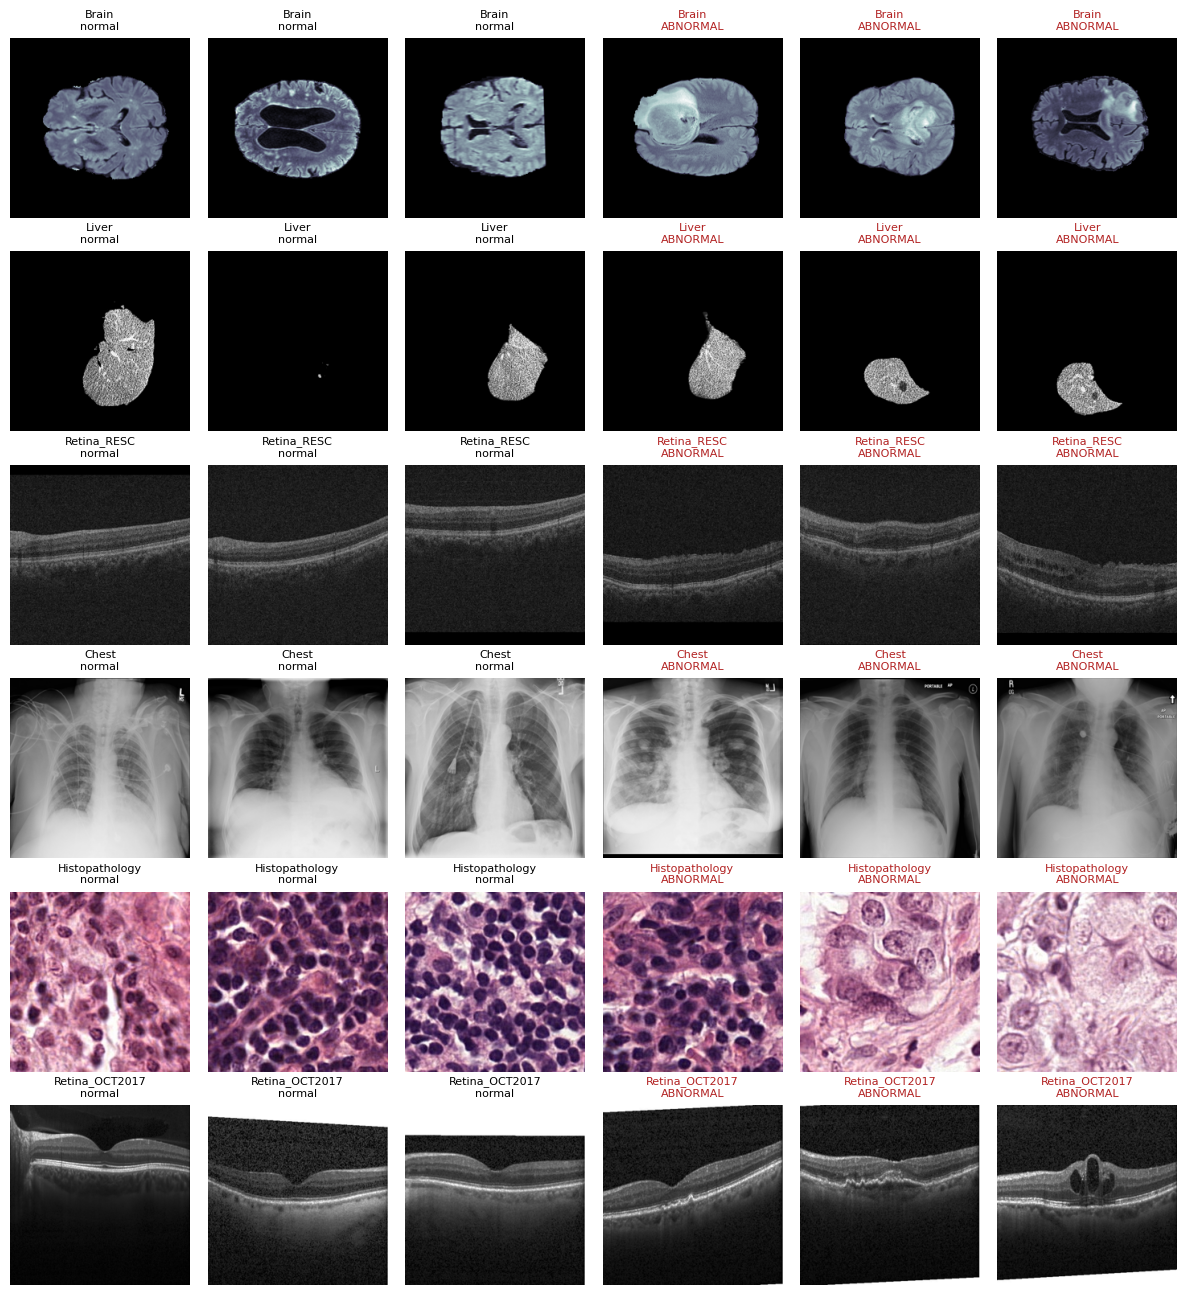

In [ ]:
# Random sample images per category (3 normal, 3 abnormal)
import random, numpy as np, matplotlib.pyplot as plt
from PIL import Image
rng = random.Random(0)
fig, axes = plt.subplots(6, 6, figsize=(12, 13))
for r, k in enumerate(CATS):
    c = BI.build_category(BMAD, k, seed=0)
    norm_, abn_ = [p for p in c['train'] if p[1] == 0], [p for p in c['train'] if p[1] == 1]
    picks = rng.sample(norm_, min(3, len(norm_))) + rng.sample(abn_, min(3, len(abn_)))
    for col, (p, y) in enumerate(picks):
        axes[r, col].imshow(Image.open(p).convert('RGB')); axes[r, col].axis('off')
        axes[r, col].set_title(f"{c['name'].replace('_AD', '')}\n{'ABNORMAL' if y else 'normal'}", fontsize=8,
                               color='firebrick' if y else 'black')
plt.tight_layout(); plt.savefig(f'{OUT}/report/sample_images.png', dpi=120); plt.show()

### Source-confound check
Share of non-black pixels per class. A large normal-vs-abnormal gap means a model could separate the classes by image *appearance* (or source) rather than pathology. The last two rows compare liver **before** (BTCV normals mixed in, as in v1/v2) and **after** the fix. Keep this table for the meeting: it documents why the liver fix was needed.

In [ ]:
import random, numpy as np
from PIL import Image
rng = random.Random(0)

def tissue(c, n=200):
    out = {}
    for lab in (0, 1):
        ps = [p for p, y in c['train'] if y == lab]
        ps = rng.sample(ps, min(n, len(ps)))
        vals = []
        for p in ps:
            with Image.open(p) as im:
                vals.append(np.mean(np.asarray(im.convert('L')) > 10))
        out['abnormal' if lab else 'normal'] = float(np.mean(vals)) if vals else float('nan')
    out['difference'] = out['abnormal'] - out['normal']
    return out

rows = {BI.CATEGORY_DISPLAY[k]: tissue(BI.build_category(BMAD, k, seed=0)) for k in CATS}
rows['Liver_AD (v1/v2: BTCV normals mixed in)'] = tissue(BI.build_category(BMAD, 'liver', seed=0, use_train_normals=True))
tissue_tab = pd.DataFrame(rows).T.round(3); display(tissue_tab)
tissue_tab.to_csv(f'{OUT}/report/tissue_fraction_check.csv')

,normal,abnormal,difference
Brain_AD,0.287,0.293,0.005
Liver_AD,0.064,0.063,-0.001
Retina_RESC_AD,0.967,0.964,-0.003
Chest_AD,0.932,0.933,0.001
Histopathology_AD,1.000,1.000,-0.000
Retina_OCT2017_AD,0.850,0.894,0.044
Liver_AD (v1/v2: BTCV normals mixed in),0.064,0.063,-0.001


In [ ]:
# Pipeline test on the validation split (a few iterations per task); must write 21 metric rows
!rm -f /content/debug_metrics.jsonl
!cd {MAMMOTH} && python main.py --dataset seq-bmad --model derpp --buffer_size 50 --alpha 0.1 --beta 0.5 --lr 0.01 --optim_mom 0.9 --n_epochs 1 --batch_size 32 --debug_mode 1 --num_workers 2 --seed 0 --non_verbose 1 --base_path /content/mammoth_data/ --bmad_root {BMAD} --bmad_eval_split val --bmad_metrics_file /content/debug_metrics.jsonl 2>&1 | tail -4
n_rows = sum(1 for _ in open('/content/debug_metrics.jsonl')) if os.path.exists('/content/debug_metrics.jsonl') else 0
print(f'{n_rows} metric rows (expected 21)')
assert n_rows == 21, 'Pipeline test failed: fix this before Part 4.'

[INFO] 01-Nov-26 08:41:41 - 	Average GPU 0 memory usage: 2492.00 MB
[INFO] 01-Nov-26 08:41:41 - 	Final GPU 0 memory usage: 2496.00 MB
[INFO] 01-Nov-26 08:41:41 - 	Max GPU 0 memory usage: 2492.00 MB
[INFO] 01-Nov-26 08:41:41 - Logging results and arguments in /content/mammoth_data/results/domain-il/seq-bmad/derpp/logs.pyd
21 metric rows (expected 21)


## Part 4 — Experiments
**Protocol:** (1) tune each method's own hyperparameters on the **validation** split (seed 0) → (2) select the best validation configuration → (3) run the selected configurations on the **test** split with 3 seeds, plus Joint-Train and Multi-Model → (4) task-order sensitivity. Learning rate, epochs, batch size, backbone and buffer size are fixed across methods.

| Tuned | Grid |
|---|---|
| DER++ | α ∈ {0.1, 0.3}, β ∈ {0.5, 1.0} |
| EWC-online | λ ∈ {10, 100, 1000} |
| SI | c ∈ {0.1, 0.5, 1.0} |

**Time:** about 1.3 h tuning + about 1 h per seed + about 35 min task order, roughly **5 hours in total**, usually across several Colab sessions. Just **Run all** each time.

In [ ]:
runner = E.Runner(mammoth_dir=MAMMOTH, bmad_root=BMAD, base_path=f'{OUT}/mammoth_data/',
                  metrics_file=f'{OUT}/metrics.jsonl', log_dir=f'{OUT}/logs', env_dir=f'{OUT}/env',
                  pred_dir=f'{OUT}/predictions', code_dirs={'bmad_cl': REPO_DIR, 'mammoth': MAMMOTH})
print('Metrics log:', runner.metrics_file)

Metrics log: /content/drive/MyDrive/CL_BMAD_project/v4_1/metrics.jsonl


In [ ]:
# Stage 1: tuning on the VALIDATION split
if RUN_TUNING:
    E.run_tuning(runner)
else:
    print('Skipped (RUN_TUNING = False): defaults will be used for every method')

[run ] tune__derpp__alpha0.1_beta0.5__s0
       ok in 9.9 min
[run ] tune__derpp__alpha0.1_beta1.0__s0
       ok in 9.9 min
[run ] tune__derpp__alpha0.3_beta0.5__s0
       ok in 9.8 min
[run ] tune__derpp__alpha0.3_beta1.0__s0
       ok in 9.9 min
[run ] tune__ewc_on__e_lambda10__s0
       ok in 5.9 min
[run ] tune__ewc_on__e_lambda100__s0
       ok in 6.0 min
[run ] tune__ewc_on__e_lambda1000__s0
       FAILED (code 1) after 5.3 min; see /content/drive/MyDrive/CL_BMAD_project/v4_1/logs/tune__ewc_on__e_lambda1000__s0.log
Raw accuracy values: Domain-IL [56.99999999999999, 70.8]


[INFO] 01-Nov-26 09:35:04 - Using 2 workers for the dataloader.
[INFO] 01-Nov-26 09:35:04 - Using 2 workers for the dataloader.
[INFO] 01-Nov-26 09:35:05 - Task 3
STOP ITERATION
STOP ITERATION
STOP ITERATION
STOP ITERATION
STOP ITERATION
Accuracy for 3 task(s): [Domain-IL]: 71.16 %
[INFO] 01-Nov-26 09:35:44 - Accuracy for 3 task(s): [Domain-IL]: 71.16 %
	Raw accuracy values: Domain-IL [55.00000000000001, 67.4, 

In [ ]:
# Stage 2: selection (validation FAA-AUROC). The test set has not been touched yet.
val_df = A.load(runner.metrics_file, eval_split='val') if os.path.exists(runner.metrics_file) else None
if val_df is not None and len(val_df):
    sel = []
    for m in E.TUNING_GRID:
        for tag, _ in E.grid_configs(m):
            g = val_df[val_df['run'] == E.tuning_run_name(m, tag)]
            if len(g) and g['after_task'].max() == E.N_TASKS:
                sel.append({'method': m, 'config': tag, 'val FAA-AUROC': round(A.cl_scores(A.matrix(g, 'auroc'))['FAA'], 4)})
    sel = pd.DataFrame(sel)
    sel['selected'] = [E.select_best(val_df, m)[0] == t for m, t in zip(sel['method'], sel['config'])]
    display(sel); sel.to_csv(f'{OUT}/report/tuning_selection.csv', index=False)
METHODS = E.final_methods(val_df)
for m, a in METHODS.items():
    print(f'{m:7s} {a}')

,method,config,val FAA-AUROC,selected
0,derpp,alpha0.1_beta0.5,0.8909,True
1,derpp,alpha0.1_beta1.0,0.8561,False
2,derpp,alpha0.3_beta0.5,0.8808,False
3,derpp,alpha0.3_beta1.0,0.8748,False
4,ewc_on,e_lambda10,0.6989,True
5,ewc_on,e_lambda100,0.5879,False
6,si,c0.1,0.5793,False
7,si,c0.5,0.6129,False
8,si,c1.0,0.6148,True


sgd     --model sgd
er      --model er --buffer_size 200
derpp   --model derpp --buffer_size 200 --alpha 0.1 --beta 0.5
agem    --model agem --buffer_size 200
ewc_on  --model ewc_on --gamma 1.0 --e_lambda 10
si      --model si --xi 1.0 --c 1.0


In [ ]:
# Stage 3: final runs on the TEST split (seed by seed; each seed completes before the next)
E.run_final(runner, METHODS, SEEDS, CATS)

[run ] sgd_s0
       ok in 5.2 min
[run ] er_s0
       ok in 8.0 min
[run ] derpp_s0
       ok in 10.5 min
[run ] agem_s0
       ok in 6.4 min
[run ] ewc_on_s0
       ok in 6.6 min
[run ] si_s0
       ok in 5.2 min
[run ] joint_s0
       ok in 3.7 min
[run ] single_brain_s0
       ok in 1.2 min
[run ] single_liver_s0
       ok in 0.5 min
[run ] single_resc_s0
       ok in 0.7 min
[run ] single_chest_s0
       ok in 1.2 min
[run ] single_histo_s0
       ok in 0.9 min
[run ] single_oct_s0
       ok in 0.7 min
[run ] sgd_s1
       ok in 5.1 min
[run ] er_s1
       ok in 8.1 min
[run ] derpp_s1
       ok in 10.6 min
[run ] agem_s1
       ok in 6.5 min
[run ] ewc_on_s1
       ok in 6.7 min
[run ] si_s1
       ok in 5.2 min
[run ] joint_s1
       ok in 3.7 min
[run ] single_brain_s1
       ok in 1.1 min
[run ] single_liver_s1
       ok in 0.5 min
[run ] single_resc_s1
       ok in 0.7 min
[run ] single_chest_s1
       ok in 1.2 min
[run ] single_histo_s1
       ok in 0.9 min
[run ] single_oc

{'sgd_s0': 'ok',
 'er_s0': 'ok',
 'derpp_s0': 'ok',
 'agem_s0': 'ok',
 'ewc_on_s0': 'ok',
 'si_s0': 'ok',
 'joint_s0': 'ok',
 'single_brain_s0': 'ok',
 'single_liver_s0': 'ok',
 'single_resc_s0': 'ok',
 'single_chest_s0': 'ok',
 'single_histo_s0': 'ok',
 'single_oct_s0': 'ok',
 'sgd_s1': 'ok',
 'er_s1': 'ok',
 'derpp_s1': 'ok',
 'agem_s1': 'ok',
 'ewc_on_s1': 'ok',
 'si_s1': 'ok',
 'joint_s1': 'ok',
 'single_brain_s1': 'ok',
 'single_liver_s1': 'ok',
 'single_resc_s1': 'ok',
 'single_chest_s1': 'ok',
 'single_histo_s1': 'ok',
 'single_oct_s1': 'ok',
 'sgd_s2': 'ok',
 'er_s2': 'ok',
 'derpp_s2': 'ok',
 'agem_s2': 'ok',
 'ewc_on_s2': 'ok',
 'si_s2': 'ok',
 'joint_s2': 'ok',
 'single_brain_s2': 'ok',
 'single_liver_s2': 'ok',
 'single_resc_s2': 'ok',
 'single_chest_s2': 'ok',
 'single_histo_s2': 'ok',
 'single_oct_s2': 'ok'}

### Stage 3b: Joint-Train reference (tuned on validation)
Joint training on all six categories at once is the upper bound, so it must be trained well. Its learning rate and an optional step decay (×0.1 after epochs 3 and 4) are tuned on the **validation** split, then the best setting is run on the **test** split with the same 3 seeds. These runs are named `joint_tuned_s*` and replace the untuned joint runs in every table.

In [ ]:
if RUN_JOINT_TUNING:
    E.run_joint_tuning(runner)
    val_df = A.load(runner.metrics_file, eval_split='val')
    jsel = []
    for tag, lr, extra in E.joint_configs():
        g = val_df[val_df['run'] == E.joint_tuning_run_name(tag)]
        if g['eval_task'].nunique() == E.N_TASKS:
            jsel.append({'config': tag, 'val mean AUROC': round(g['auroc'].mean(), 4),
                         'worst category': round(g['auroc'].min(), 4)})
    jsel = pd.DataFrame(jsel); display(jsel); jsel.to_csv(f'{OUT}/report/joint_tuning_selection.csv', index=False)
    best = E.select_joint(val_df)
    print('Selected Joint-Train configuration:', best)
    E.run_joint_final(runner, best[0], SEEDS)
else:
    print('Skipped (RUN_JOINT_TUNING = False)')

[run ] tune__joint__lr0.01_const__s0
       ok in 3.6 min
[run ] tune__joint__lr0.003_const__s0
       ok in 3.5 min
[run ] tune__joint__lr0.01_step__s0
       ok in 3.5 min
[run ] tune__joint__lr0.003_step__s0
       ok in 3.5 min
[run ] tune__joint__lr0.001_step__s0
       ok in 3.5 min


,config,val mean AUROC,worst category
0,lr0.01_const,0.9261,0.8095
1,lr0.003_const,0.9213,0.7172
2,lr0.01_step,0.9334,0.7953
3,lr0.003_step,0.9352,0.7978
4,lr0.001_step,0.9299,0.8066


Selected Joint-Train configuration: ('lr0.003_step', 0.9351885239820447)
[run ] joint_tuned_s0
       ok in 3.7 min
[run ] joint_tuned_s1
       ok in 3.7 min
[run ] joint_tuned_s2
       ok in 3.7 min


### Stage 3c: EWC sensitivity (λ = 10)
Online EWC at its validation-selected strength (λ = 1000) diverged reproducibly on one test seed in v3. Validation's second-best setting runs here on all seeds, labelled `ewc-on {lambda10}` in the tables. Learning rate and other shared settings stay fixed, so the comparison remains fair.

In [ ]:
if RUN_EWC_SENSITIVITY:
    E.run_ewc_sensitivity(runner, SEEDS)
else:
    print('Skipped (RUN_EWC_SENSITIVITY = False)')

[run ] ewc_on_lambda10_s0
       ok in 7.0 min
[run ] ewc_on_lambda10_s1
       ok in 6.8 min
[run ] ewc_on_lambda10_s2
       ok in 6.9 min


In [ ]:
# Stage 4: task-order sensitivity (test split, seed 0)
if RUN_TASK_ORDER:
    E.run_orders(runner, METHODS)
else:
    print('Skipped (RUN_TASK_ORDER = False)')

[run ] sgd_rev_s0
       ok in 5.2 min
[run ] derpp_rev_s0
       ok in 10.7 min
[run ] sgd_mix_s0
       ok in 5.3 min
[run ] derpp_mix_s0
       ok in 10.7 min


## Part 5 — Report
- **Tables:** mean [95% t-interval over seeds]. With 3 seeds the intervals are wide by design (t = 4.30); they show how much the seed alone moves a result.
- **Paired comparisons:** same-seed differences between methods. *Interval excludes zero* means a consistent difference across seeds.
- **Bootstrap:** test-set sampling uncertainty for each run, from saved per-image predictions.

Everything is written to `MyDrive/CL_BMAD/v3/report` (CSV, Markdown and PNG).


=== AUROC (test split) ===


,FAA,AvgACC,BWT,Forgetting,Gap to joint,n seeds
method,,,,,,
agem (buffer 200),"0.722 [0.589, 0.855]","0.752 [0.700, 0.805]","-0.192 [-0.369, -0.014]","0.196 [0.027, 0.366]",0.244,3
derpp (buffer 200),"0.915 [0.881, 0.950]","0.915 [0.881, 0.949]","-0.008 [-0.024, 0.008]","0.018 [-0.009, 0.045]",0.050,3
"derpp (buffer 200) [order: chest,brain,oct,liver,histo,resc]",0.924,0.931,-0.012,0.012,0.041,1
"derpp (buffer 200) [order: oct,histo,chest,resc,liver,brain]",0.922,0.944,-0.032,0.039,0.044,1
er (buffer 200),"0.914 [0.879, 0.950]","0.934 [0.925, 0.943]","-0.032 [-0.080, 0.016]","0.038 [-0.022, 0.099]",0.051,3
ewc-on,"0.648 [0.527, 0.769]","0.700 [0.675, 0.724]","-0.281 [-0.345, -0.217]","0.281 [0.217, 0.345]",0.317,3
ewc-on {lambda10},"0.636 [0.586, 0.685]","0.697 [0.669, 0.725]","-0.319 [-0.383, -0.255]","0.319 [0.255, 0.383]",0.330,3
sgd,"0.612 [0.579, 0.645]","0.698 [0.663, 0.732]","-0.342 [-0.384, -0.300]","0.342 [0.300, 0.384]",0.353,3
"sgd [order: chest,brain,oct,liver,histo,resc]",0.544,0.673,-0.435,0.435,0.422,1



=== F1 (test split) ===


,FAA,AvgACC,BWT,Forgetting,Gap to joint,n seeds
method,,,,,,
agem (buffer 200),"0.626 [0.307, 0.946]","0.643 [0.577, 0.710]","-0.129 [-0.559, 0.302]","0.146 [-0.254, 0.547]",0.282,3
derpp (buffer 200),"0.817 [0.705, 0.928]","0.816 [0.727, 0.905]","-0.039 [-0.165, 0.086]","0.050 [-0.096, 0.197]",0.092,3
"derpp (buffer 200) [order: chest,brain,oct,liver,histo,resc]",0.845,0.859,-0.038,0.038,0.063,1
"derpp (buffer 200) [order: oct,histo,chest,resc,liver,brain]",0.850,0.871,-0.033,0.060,0.059,1
er (buffer 200),"0.850 [0.824, 0.876]","0.860 [0.844, 0.876]","-0.017 [-0.059, 0.026]","0.035 [0.025, 0.045]",0.058,3
ewc-on,"0.270 [0.129, 0.411]","0.518 [0.344, 0.692]","-0.628 [-0.700, -0.556]","0.628 [0.556, 0.700]",0.639,3
ewc-on {lambda10},"0.481 [0.029, 0.933]","0.543 [0.474, 0.612]","-0.400 [-1.002, 0.201]","0.403 [-0.206, 1.013]",0.428,3
sgd,"0.419 [0.012, 0.826]","0.589 [0.428, 0.750]","-0.456 [-0.909, -0.003]","0.456 [0.003, 0.909]",0.490,3
"sgd [order: chest,brain,oct,liver,histo,resc]",0.139,0.415,-0.719,0.719,0.770,1



=== ACC (test split) ===


,FAA,AvgACC,BWT,Forgetting,Gap to joint,n seeds
method,,,,,,
agem (buffer 200),"0.651 [0.544, 0.758]","0.682 [0.640, 0.724]","-0.158 [-0.360, 0.045]","0.166 [-0.005, 0.337]",0.262,3
derpp (buffer 200),"0.838 [0.777, 0.898]","0.836 [0.785, 0.887]","-0.018 [-0.070, 0.035]","0.032 [-0.044, 0.109]",0.075,3
"derpp (buffer 200) [order: chest,brain,oct,liver,histo,resc]",0.853,0.861,-0.029,0.029,0.060,1
"derpp (buffer 200) [order: oct,histo,chest,resc,liver,brain]",0.861,0.876,-0.013,0.048,0.052,1
er (buffer 200),"0.856 [0.840, 0.873]","0.867 [0.852, 0.882]","-0.009 [-0.059, 0.041]","0.033 [0.004, 0.063]",0.057,3
ewc-on,"0.589 [0.510, 0.668]","0.648 [0.624, 0.671]","-0.266 [-0.382, -0.151]","0.266 [0.151, 0.382]",0.324,3
ewc-on {lambda10},"0.603 [0.535, 0.672]","0.654 [0.633, 0.675]","-0.264 [-0.403, -0.124]","0.264 [0.124, 0.403]",0.310,3
sgd,"0.560 [0.514, 0.606]","0.651 [0.623, 0.679]","-0.297 [-0.355, -0.240]","0.297 [0.240, 0.355]",0.353,3
"sgd [order: chest,brain,oct,liver,histo,resc]",0.539,0.618,-0.287,0.287,0.374,1


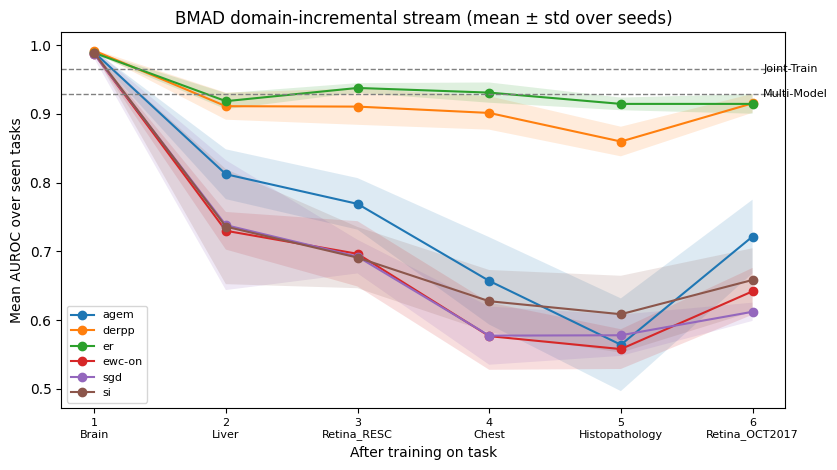

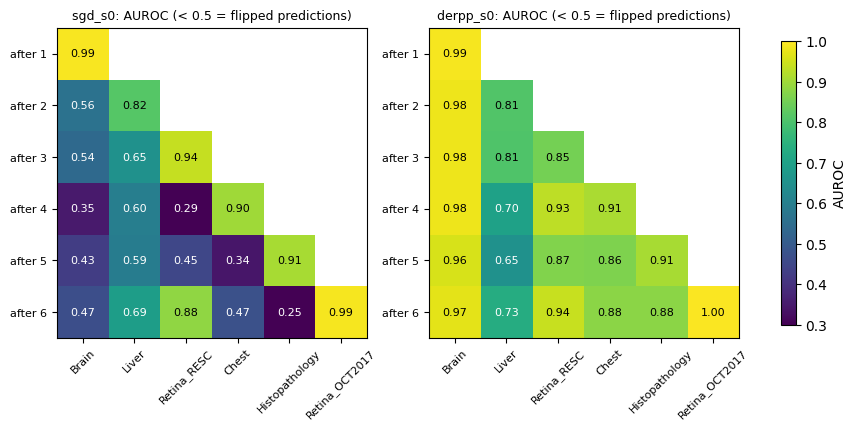

In [ ]:
res = report.make_report(runner.metrics_file, f'{OUT}/report', pred_dir=runner.pred_dir, order=BI.DEFAULT_ORDER)
for metric in ['auroc', 'f1', 'acc']:
    if f'summary_{metric}' in res:
        print(f'\n=== {metric.upper()} (test split) ==='); display(res[f'summary_{metric}'])

In [ ]:
import matplotlib.pyplot as plt
print('Incomplete runs (excluded from means, reported):'); display(res.get('incomplete'))
print('Final AUROC per category (mean over seeds):'); display(res.get('per_category'))
print('Paired same-seed comparisons (FAA-AUROC, a - b):'); display(res.get('comparisons'))
if 'bootstrap' in res:
    print('Bootstrap 95% intervals of final mean AUROC (seed 0 runs):')
    bt = res['bootstrap']; display(bt[bt['run'].str.endswith('_s0')].round(4))
    print('Joint-Train (tuned) bootstrap intervals:'); display(bt[bt['run'].str.startswith('joint_tuned')].round(4))
plt.show()

Incomplete runs (excluded from means, reported):


,run,method,seed,tasks_done


Final AUROC per category (mean over seeds):


category,Brain_AD,Liver_AD,Retina_RESC_AD,Chest_AD,Histopathology_AD,Retina_OCT2017_AD
model,,,,,,
agem,0.599,0.617,0.846,0.587,0.691,0.990
derpp,0.976,0.811,0.948,0.891,0.874,0.993
er,0.980,0.811,0.936,0.883,0.879,0.999
ewc-on,0.580,0.562,0.792,0.489,0.444,0.985
sgd,0.521,0.592,0.800,0.447,0.399,0.914
si,0.562,0.723,0.656,0.488,0.532,0.991
[ref] Joint-Train,0.992,0.931,0.988,0.929,0.956,0.998
[ref] Multi-Model,0.990,0.888,0.945,0.897,0.858,0.999


Paired same-seed comparisons (FAA-AUROC, a - b):


,a,b,score,diff,lo,hi,n_pairs,interval_excludes_zero
0,er (buffer 200),derpp (buffer 200),auroc_FAA,-0.000888,-0.056449,0.054673,3,False
1,derpp (buffer 200),sgd,auroc_FAA,0.303219,0.239103,0.367334,3,True


Bootstrap 95% intervals of final mean AUROC (seed 0 runs):


,run,mean_auroc,lo,hi,n_categories,resampling_unit
0,agem_s0,0.7401,0.7010,0.7724,6,group
3,derpp_mix_s0,0.9244,0.9010,0.9380,6,group
4,derpp_rev_s0,0.9216,0.9031,0.9377,6,group
5,derpp_s0,0.8996,0.8782,0.9214,6,group
8,er_s0,0.9207,0.9049,0.9345,6,group
11,ewc_on_lambda10_s0,0.6217,0.5949,0.6458,6,group
14,ewc_on_s0,0.6470,0.6196,0.6720,6,group
17,joint_s0,0.9549,0.9313,0.9679,6,group
20,joint_tuned_s0,0.9630,0.9512,0.9711,6,group
23,sgd_mix_s0,0.5438,0.5225,0.5630,6,group


Joint-Train (tuned) bootstrap intervals:


,run,mean_auroc,lo,hi,n_categories,resampling_unit
20,joint_tuned_s0,0.9630,0.9512,0.9711,6,group
21,joint_tuned_s1,0.9678,0.9606,0.9736,6,group
22,joint_tuned_s2,0.9660,0.9579,0.9725,6,group


In [ ]:
# Provenance of the final runs: environment as recorded by each run
import json, glob
envs = [json.load(open(p)) for p in sorted(glob.glob(f'{OUT}/env/*.json'))]
if envs:
    e = envs[-1]
    print(f"{len(envs)} runs recorded | GPU: {e.get('gpu')} | torch {e.get('torch')} | CUDA {e.get('cuda')} | python {e.get('python')}")
    print('code commits:', e.get('code_commits'))

64 runs recorded | GPU: Tesla T4 | torch 2.11.0+cu130 | CUDA 13.0 | python 3.13.16
code commits: {'bmad_cl': None, 'mammoth': 'e75a491c69fd729edeb01431afb753d9157d9a81'}


## Part 6 (optional) — PyCLAD
Off by default; use a fresh runtime for real PyCLAD work (its vision extras change library versions Mammoth relies on). PyCLAD includes `PatchCore` and generic strategies but **no class named PatchCoreCL**, so ask Prof. Corizzo which combination reproduces Barusco et al.

In [ ]:
if RUN_PYCLAD:
    !pip install -q "pyclad[vision] @ git+https://github.com/lifelonglab/pyCLAD.git@b36d7eb9504b6fcef4f8870fd999d63348105338"
    from pyclad.vision.models.patchcore.patchcore import PatchCore
    print('PyCLAD OK')
else:
    print('Skipped (RUN_PYCLAD = False)')

Skipped (RUN_PYCLAD = False)
